<a href="https://colab.research.google.com/github/jelvalojel-glitch/ML_task_05/blob/main/task05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)

# 1. Загрузка CSV
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print("Размер датасета:", df.shape)
display(df.head())
print("Столбцы:", df.columns.tolist())

# ИЗМЕНИ на название целевого столбца из своего датасета
TARGET = "hypertension"

# Предполагается, что целевая переменная содержит классы 0 и 1
df = df.dropna(subset=[TARGET]).copy()
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

assert set(y.unique()) == {0, 1}, (
    "Целевая переменная должна содержать классы 0 и 1. "
    "Если у тебя другие метки, их нужно преобразовать."
)

# 2. Числовые и категориальные признаки
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight=None
    ))
])

# 60% обучение, 20% подбор порога, 20% итоговая проверка
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    random_state=42, stratify=y_trainval
)

model.fit(X_train, y_train)

# Вероятности принадлежности к классу 1
p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

print("Обучение завершено.")
print("Размеры:", len(X_train), len(X_val), len(X_test))
print("Доля класса 1:", round(y.mean(), 3))


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
Размер датасета: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Столбцы: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
Обучение завершено.
Размеры: 3066 1022 1022
Доля класса 1: 0.097


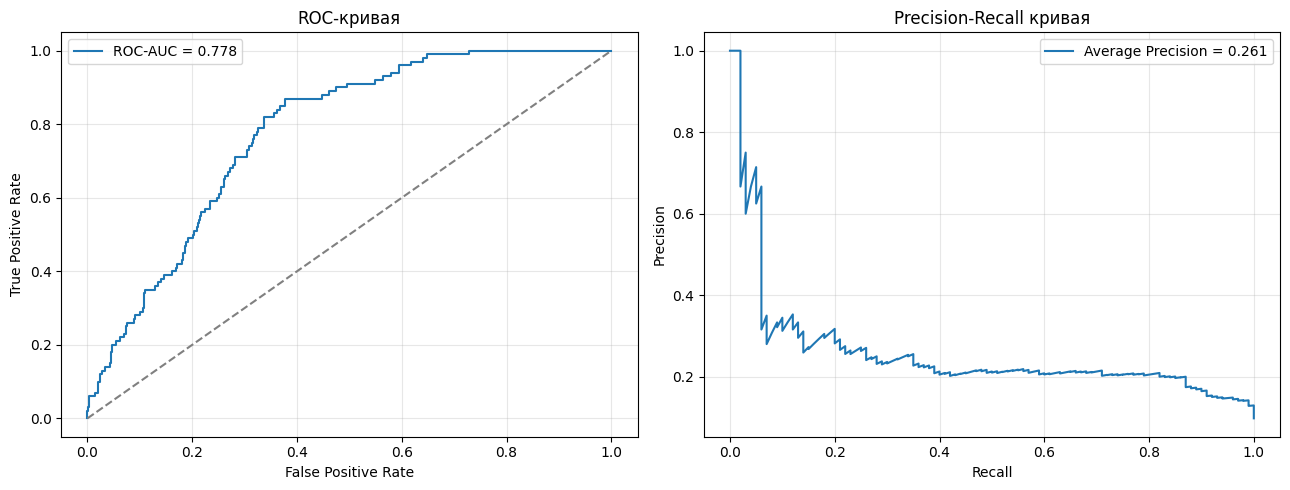

ROC-AUC: 0.7776
PR-AUC (Average Precision): 0.2608


In [5]:

# ROC-кривая и ROC-AUC
fpr, tpr, _ = roc_curve(y_test, p_test)
roc_auc = roc_auc_score(y_test, p_test)

# PR-кривая и Average Precision
precision_vals, recall_vals, _ = precision_recall_curve(y_test, p_test)
pr_auc = average_precision_score(y_test, p_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(
    title="ROC-кривая", xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(recall_vals, precision_vals,
             label=f"Average Precision = {pr_auc:.3f}")
axes[1].set(
    title="Precision-Recall кривая",
    xlabel="Recall", ylabel="Precision"
)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")


Порог по умолчанию: 0.50
Подобранный порог:  0.139
Минимальная цена ошибок на validation: 346


,Порог,Accuracy,Precision,Recall,F1,FP,FN,Цена ошибок
Порог 0.5,0.500,0.904,0.600,0.06,0.109,4,94,474
Подобранный порог,0.139,0.750,0.211,0.57,0.308,213,43,428


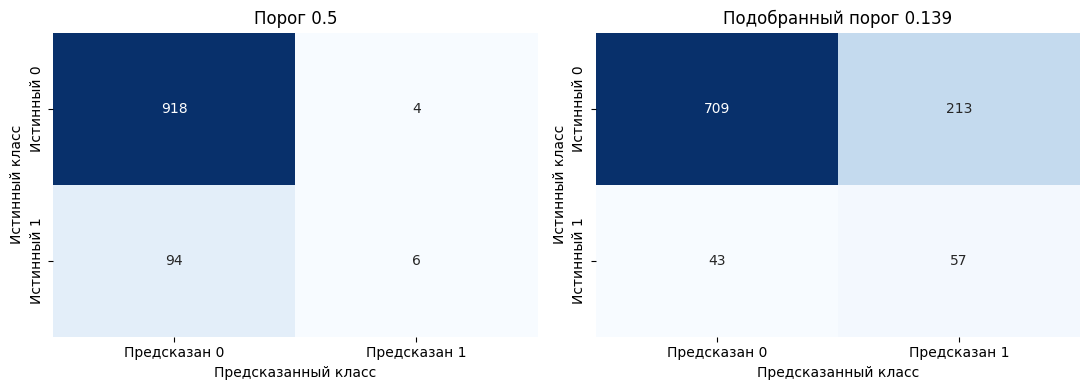

In [6]:

# УКАЖИ ЦЕНУ ОШИБОК ИЗ УСЛОВИЯ ПРЕПОДАВАТЕЛЯ
FP_COST = 1    # цена ложноположительного результата
FN_COST = 5    # цена ложноотрицательного результата

# Подбираем порог на validation-выборке, а не на тестовой
thresholds = np.r_[0.0, np.unique(p_val), 1.0]

costs = []
for t in thresholds:
    pred = (p_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()
    costs.append(fp * FP_COST + fn * FN_COST)

best_threshold = thresholds[np.argmin(costs)]

print(f"Порог по умолчанию: 0.50")
print(f"Подобранный порог:  {best_threshold:.3f}")
print(f"Минимальная цена ошибок на validation: {min(costs):.0f}")

# Оценка на тесте при обоих порогах
pred_default = (p_test >= 0.5).astype(int)
pred_tuned = (p_test >= best_threshold).astype(int)

def get_metrics(y_true, pred, probs, threshold):
    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()
    return {
        "Порог": round(float(threshold), 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Цена ошибок": fp * FP_COST + fn * FN_COST
    }

results = pd.DataFrame([
    get_metrics(y_test, pred_default, p_test, 0.5),
    get_metrics(y_test, pred_tuned, p_test, best_threshold)
], index=["Порог 0.5", "Подобранный порог"])

display(results.round(3))

# Матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, title in zip(
    axes,
    [pred_default, pred_tuned],
    ["Порог 0.5", f"Подобранный порог {best_threshold:.3f}"]
):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Предсказан 0", "Предсказан 1"],
        yticklabels=["Истинный 0", "Истинный 1"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()
